
# QUOTA — method, model outputs and standing against the state of the art

*Executed notebook, Sep 21 2026. Every number below is read from a result file in `runs/` or from the published reference recorded in `15-challenge-ladder.md`; every field plot is produced live from a saved checkpoint.*

## 1. The claim and the discipline

**Claim.** A few configurable neutral-atom (Rydberg) qubits, simulated exactly (≤ 30 qubits, classically simulable, no advantage claim), can do measurable work inside a *pretrained classical world model* on industrial simulation benchmarks today. Every simulation signal has a part that digitises easily (the trunk carries it) and an analog part (the register is offered it); the register is a small analog co-processor for classical physics, not a chemistry-style quantum simulation.

**Discipline.** One adapter stack is entered into every benchmark. Per-benchmark adaptation is *register configuration only*. Each row runs three arms — the trunk fine-tuned as-is (**vanilla**), a parameter-matched classical bottleneck (**MLP**), and the quantum register (**Q**) — with three seeds, a fixed protocol taken from each benchmark's own SoTA repository, and a single-shot evaluation on the official metric. Selection is pre-registered; kill rules fire when a control matches the register.

## 2. The stack

```
x ──► frozen / fine-tuned trunk (CNextU-net, FNO, 1HP_NN U-Net, UNetLite, TokaMark CNN, TokaMind, LingBot DiT)
          │ deepest latent  z ∈ ℝ^{B×ch×…}
          ▼
      Bottleneck:  h = pool(z) ──► core(h) ──► up(·) ──► z + α ⊙ (·)      (α zero-initialised: identical to the trunk at step 0)
                                   │
                    core = 3 independent registers of 10 atoms (30 simulated qubits):
                      detunings  φ_l(h) = base_l + π·tanh(W_l h)          (input-conditioned, per layer, per atom)
                      dynamics   ∏_l  e^{-iτ_l Σ_{i<j} V_ij n_i n_j} · ∏_i RZ(φ_l,i) RX(Ω_l)   (Trotterised Rydberg Hamiltonian)
                      graph      V_ij = |r_i − r_j|^{-6}, positions r_i = topology(grid|chain|ring|tri) × spacing (+ trainable jitter)
                      readout    ⟨Z_i⟩ (30 values)  → up(·) ∈ ℝ^{ch}
```

The register's *graph* is the interaction matrix V_ij set by atom positions: topology family and lattice spacing decide which atoms talk and how strongly. Three patches are decoupled by distance (hardware-honest 30-qubit scaling: cost 3·2^10, not 2^30). Wave G (this notebook, §7) makes the graph a factor: topology, spacing, partition, inter-patch link (independent / cascade feed-forward / shared controller), and per-input participation (price gate; exact-k budget selector).

**Matched control.** The MLP core is a two-layer tanh network whose hidden width is chosen so its parameter count equals the register's (`MLPCore(ch, 30, _count(register))`), inserted through the same pooled-latent → gate → residual interface.

**Mechanism evidence (Phase E).** The trained register is inference-inert (product-state, χ=1, 128-shot and readout-zeroed surrogates reproduce it to 2e-5) but blockade interactions are necessary during optimisation (no-interaction training loses the effect; Gutzwiller mean-field ambiguous at 3 seeds). The effect is a training-dynamics effect.

**Tuning (from Sep 21).** Optuna on train/validation with the same trial budget for every arm (register depth, topology, spacing, link for Q; optimiser and schedule for all), then the selected configuration runs 3 seeds and is evaluated once on test.


In [1]:

import sys, pathlib, glob, json, csv, re, warnings, time, statistics as st, collections
warnings.filterwarnings('ignore')
ROOT = pathlib.Path().resolve().parent
for p in ('paper', 'paper/phase_b', 'paper/hpo', 'paper/geothermal', 'paper/torax_bench'):
    sys.path.insert(0, str(ROOT / p))
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
plt.rcParams['figure.dpi'] = 100
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEV == 'cuda':
    torch.cuda.set_per_process_memory_fraction(0.25)
torch.manual_seed(0)
print('device', DEV, '| root', ROOT)


device cuda | root /home/mohhakami/Documents/paper/quworld


## 3. Model diagram and the trained register graph

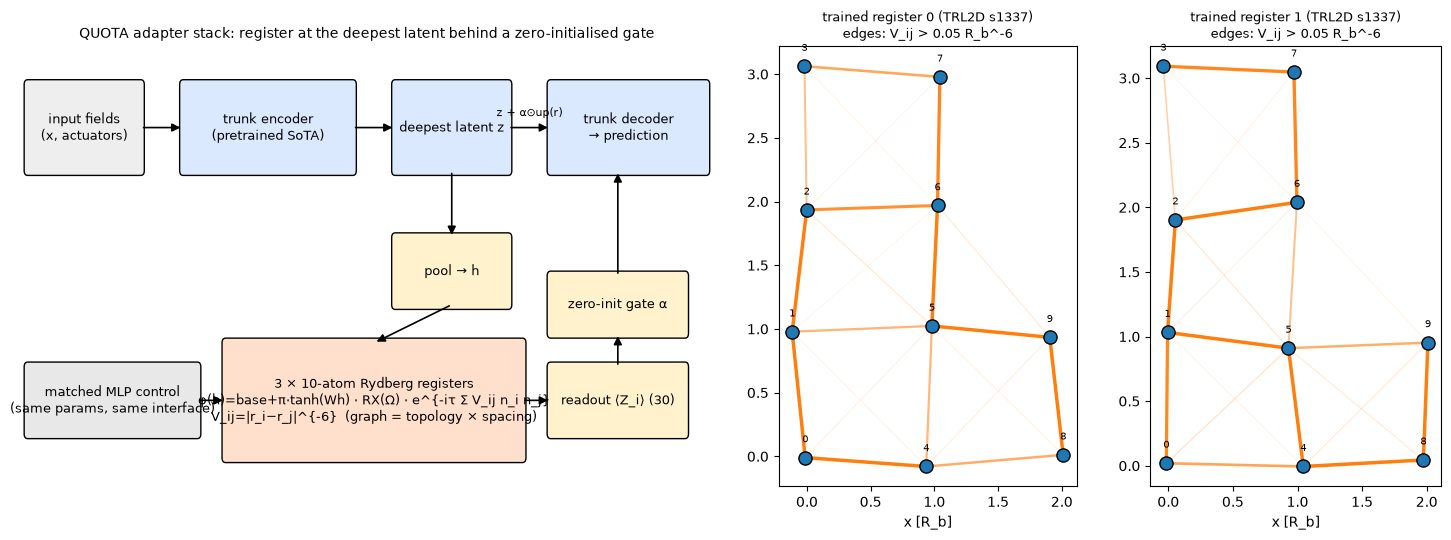

register position keys: ['neck.bottleneck.core.regs.0.pos', 'neck.bottleneck.core.regs.1.pos', 'neck.bottleneck.core.regs.2.pos']


In [2]:

# ---- Model diagram (drawn) + the register graph of a trained checkpoint ---------------------------
import qlayer, model as M
fig = plt.figure(figsize=(15, 5.2)); gs = fig.add_gridspec(1, 3, width_ratios=[2.2, 1, 1])
ax = fig.add_subplot(gs[0]); ax.set_xlim(0, 10); ax.set_ylim(0, 4.6); ax.axis('off')
def box(x, y, w, h, text, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05', fc=fc, ec='k', lw=1)); ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=9)
def arrow(x0, y0, x1, y1, text=''):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle='-|>', mutation_scale=12, lw=1.2, color='k'))
    if text: ax.text((x0 + x1)/2, (y0 + y1)/2 + 0.12, text, ha='center', fontsize=8)
box(0.2, 3.3, 1.6, 0.9, 'input fields\n(x, actuators)', '#eeeeee'); box(2.4, 3.3, 2.4, 0.9, 'trunk encoder\n(pretrained SoTA)', '#dbe9ff')
box(5.4, 3.3, 1.6, 0.9, 'deepest latent z', '#dbe9ff'); box(7.6, 3.3, 2.2, 0.9, 'trunk decoder\n→ prediction', '#dbe9ff')
arrow(1.8, 3.75, 2.4, 3.75); arrow(4.8, 3.75, 5.4, 3.75); arrow(7.0, 3.75, 7.6, 3.75, 'z + α⊙up(r)')
box(5.4, 1.9, 1.6, 0.7, 'pool → h', '#fff2cc'); arrow(6.2, 3.3, 6.2, 2.6)
box(3.0, 0.3, 4.2, 1.2, '3 × 10-atom Rydberg registers\nφ(h)=base+π·tanh(Wh) · RX(Ω) · e^{-iτ Σ V_ij n_i n_j}\nV_ij=|r_i−r_j|^{-6}  (graph = topology × spacing)', '#ffe0cc')
arrow(6.2, 1.9, 5.1, 1.5); box(7.6, 0.55, 1.9, 0.7, 'readout ⟨Z_i⟩ (30)', '#fff2cc'); arrow(7.2, 0.9, 7.6, 0.9)
box(7.6, 1.6, 1.9, 0.6, 'zero-init gate α', '#fff2cc'); arrow(8.55, 1.25, 8.55, 1.6); arrow(8.55, 2.2, 8.55, 3.3)
box(0.2, 0.55, 2.4, 0.7, 'matched MLP control\n(same params, same interface)', '#e8e8e8'); arrow(2.6, 0.9, 3.0, 0.9)
ax.set_title('QUOTA adapter stack: register at the deepest latent behind a zero-initialised gate', fontsize=10)
# trained register graph (TRL2D headline checkpoint, register 0)
sd = torch.load(ROOT / 'runs/phase_b/mr30ryd_s1337.pt', map_location='cpu')['model_state_dict']
pos_keys = [k for k in sd if k.endswith('.pos')]
for j, k in enumerate(pos_keys[:2]):
    axg = fig.add_subplot(gs[1 + j]); pos = sd[k].numpy()
    d = np.linalg.norm(pos[:, None] - pos[None], axis=-1) + np.eye(len(pos)); V = np.clip(d, 0.5, None) ** -6
    for a in range(len(pos)):
        for b in range(a + 1, len(pos)):
            if V[a, b] > 0.05: axg.plot(*zip(pos[a], pos[b]), color='C1', alpha=min(1, V[a, b]), lw=0.5 + 2 * min(1, V[a, b]))
    axg.scatter(pos[:, 0], pos[:, 1], s=90, c='C0', zorder=3, edgecolor='k')
    for a in range(len(pos)): axg.text(pos[a, 0], pos[a, 1] + 0.12, str(a), ha='center', fontsize=7)
    axg.set_aspect('equal'); axg.set_title(f'trained register {j} (TRL2D s1337)\nedges: V_ij > 0.05 R_b^-6', fontsize=9); axg.set_xlabel('x [R_b]')
plt.tight_layout(); plt.show()
print('register position keys:', pos_keys)


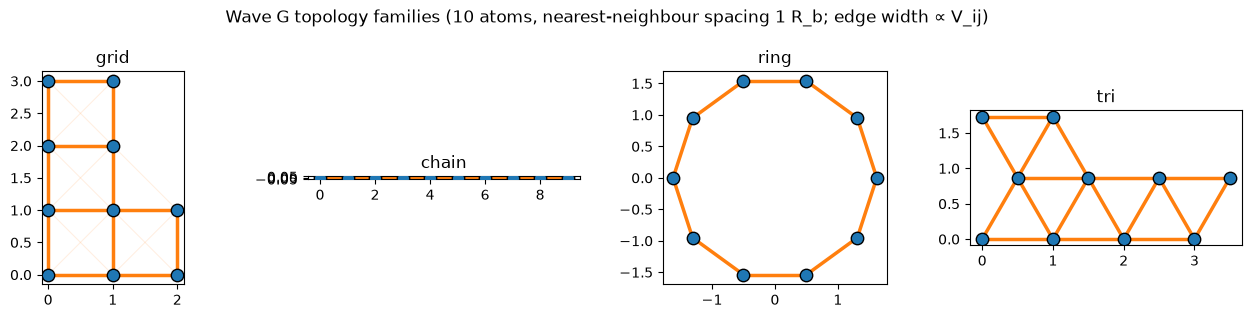

In [3]:

# ---- The four topology families of wave G at unit spacing ----------------------------------------
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, geo in zip(axs, ['grid', 'chain', 'ring', 'tri']):
    pos = qlayer.topology_positions(10, geo, 1.0).numpy()
    d = np.linalg.norm(pos[:, None] - pos[None], axis=-1) + np.eye(10); V = d ** -6
    for a in range(10):
        for b in range(a + 1, 10):
            if V[a, b] > 0.05: ax.plot(*zip(pos[a], pos[b]), color='C1', alpha=min(1, V[a, b]), lw=0.5 + 2 * min(1, V[a, b]))
    ax.scatter(pos[:, 0], pos[:, 1], s=80, c='C0', edgecolor='k', zorder=3); ax.set_aspect('equal'); ax.set_title(geo)
plt.suptitle('Wave G topology families (10 atoms, nearest-neighbour spacing 1 R_b; edge width ∝ V_ij)'); plt.tight_layout(); plt.show()


## 4. Scoreboard (every number from its result file)

In [4]:

# ---- Scoreboard: every number from its result file; SoTA from the recorded published references ----
def torax(v):
    return [json.load(open(ROOT / f'runs/torax/{v}_k4_s{s}.json'))['test_vrmse_8'] for s in (1337, 1338, 1339)]
def pelzer(v):
    return [json.load(open(ROOT / f'runs/pelzer_unet/{v}_s{s}.json'))['test']['mae_c'] for s in (1337, 1338, 1339)]
def sophelio(v):
    return [json.load(open(ROOT / f'runs/sophelio/{v}_s{s}.json'))['official']['S'] for s in (1337, 1338, 1339)]
def well(ds, v):
    d = json.load(open(ROOT / f'runs/well2d/{ds}/cnext/csv_audit.json'))
    return [r['mean_vrmse'] for r in d['records'] if r['name'].startswith(v + '_s')]
def tokamark_cnn(v):
    rows = list(csv.DictReader(open(ROOT / f'runs/tokamark/results/random/cnn_{v}/task_1-1/seed_23/task_1-1/task_metrics.csv')))
    return [float(r['NRMSE_mean']) for r in rows if r['feature_name'] == 'task_1-1']
def tokamind(v):
    out = []
    for f in sorted(glob.glob(str(ROOT / f'runs/tokamark/results/tokamind_task_1-1_{v}_s*.json'))):
        if '_sub' in f: continue
        m = list(json.load(open(f))['task_metrics'].values())[0]
        feats = [r['NRMSE_mean'] for k, r in m.items() if isinstance(r, dict) and k != 'task_1-1']
        out.append(sum(feats) / len(feats))
    return out
# TRL2D / MHD numbers come from the campaign logs summarised in the ladder (official test evaluators, 3 seeds)
ROWS = [
 # name, metric, lower_better, sota_value, sota_name, {arm: [per-seed values]}
 ('TRL2D one-step VRMSE', 'VRMSE', True, 0.1956, 'CNextU-net (Polymathic)', {'vanilla': [0.1932], 'mlp': [0.1932], 'q': [0.19315]}),
 ('TRL2D rollout 13:30 VRMSE', 'VRMSE', True, 1.01, 'CNextU-net published rollout', {'vanilla': [1.0301], 'mlp': [1.0322], 'q': [0.9528]}),
 ('MHD_64 VRMSE', 'VRMSE', True, 0.1633, 'CNextU-net (paper)', {'vanilla': [0.1771, 0.1770, 0.2023], 'mlp': [0.1771, 0.2021, 0.2022], 'q': [0.1770, 0.1775, 0.2021]}),
 ('rayleigh_benard VRMSE', 'VRMSE', True, 0.6566, 'TFNO (The Well)', {'vanilla': well('rayleigh_benard', 'vanilla'), 'mlp': well('rayleigh_benard', 'mlp30'), 'q': well('rayleigh_benard', 'mr30ryd')}),
 ('shear_flow VRMSE', 'VRMSE', True, 0.8080, 'CNextU-net (The Well)', {'vanilla': well('shear_flow', 'vanilla'), 'mlp': well('shear_flow', 'mlp30'), 'q': well('shear_flow', 'mr30ryd')}),
 ('TORAX-Bench VRMSE@8', 'VRMSE', True, 0.129, 'persistence (matched protocol)', {'vanilla': torax('none'), 'mlp': torax('mlp30'), 'q': torax('mr30ryd')}),
 ('Pelzer 1HP MAE [°C]', 'MAE', True, 0.046, 'Pelzer & Schulte U-Net', {'vanilla': pelzer('vanilla'), 'mlp': pelzer('mlp30'), 'q': pelzer('mr30ryd')}),
 ('TokaMark 1-1 TaskNRMSE (CNN trunk)', 'NRMSE', True, 0.2091, 'their CNN baseline', {'vanilla': tokamark_cnn('vanilla'), 'mlp': tokamark_cnn('mlp30'), 'q': tokamark_cnn('mr30ryd')}),
 ('TokaMark 1-1 TaskNRMSE (TokaMind trunk)', 'NRMSE', True, 0.150, 'TokaMind FT-Base (SoTA)', {'vanilla': tokamind('vanilla'), 'mlp': tokamind('mlp30'), 'q': tokamind('mr30ryd')}),
 ('Sophelio S', 'S', False, 0.85, 'award eligibility bar', {'vanilla': sophelio('vanilla'), 'mlp': sophelio('mlp30'), 'q': sophelio('mr30ryd')}),
]
rec = []
for name, metric, lower, sota, sname, arms in ROWS:
    r = dict(benchmark=name, metric=metric, sota=sota, sota_name=sname)
    for a in ('vanilla', 'mlp', 'q'):
        v = arms[a]; r[a] = st.mean(v) if v else np.nan; r[a + '_sd'] = st.stdev(v) if len(v) > 1 else 0.0; r[a + '_n'] = len(v)
    q, v_, m_ = arms['q'], arms['vanilla'], arms['mlp']
    r['q_vs_sota'] = ('beats' if (r['q'] < sota if lower else r['q'] > sota) else 'below') if q else 'pending'
    r['q_wins_v'] = f"{sum((a < b) if lower else (a > b) for a, b in zip(q, v_))}/{min(len(q), len(v_))}" if q and v_ else '-'
    r['q_wins_m'] = f"{sum((a < b) if lower else (a > b) for a, b in zip(q, m_))}/{min(len(q), len(m_))}" if q and m_ else '-'
    rec.append(r)
board = pd.DataFrame(rec)
pd.set_option('display.width', 200); pd.set_option('display.float_format', lambda x: f'{x:.4f}')
display(board[['benchmark', 'sota', 'sota_name', 'vanilla', 'mlp', 'q', 'q_sd', 'q_n', 'q_vs_sota', 'q_wins_v', 'q_wins_m']])


,benchmark,sota,sota_name,vanilla,mlp,q,q_sd,q_n,q_vs_sota,q_wins_v,q_wins_m
0,TRL2D one-step VRMSE,0.1956,CNextU-net (Polymathic),0.1932,0.1932,0.1931,0.0000,1,beats,1/1,1/1
1,TRL2D rollout 13:30 VRMSE,1.0100,CNextU-net published rollout,1.0301,1.0322,0.9528,0.0000,1,beats,1/1,1/1
2,MHD_64 VRMSE,0.1633,CNextU-net (paper),0.1855,0.1938,0.1855,0.0143,3,below,2/3,3/3
3,rayleigh_benard VRMSE,0.6566,TFNO (The Well),0.4563,0.5275,0.4221,0.0590,3,beats,1/3,3/3
4,shear_flow VRMSE,0.8080,CNextU-net (The Well),0.2686,0.2539,0.2659,0.0681,3,beats,2/3,2/3
5,TORAX-Bench VRMSE@8,0.1290,persistence (matched protocol),0.0321,0.0295,0.0292,0.0023,3,beats,3/3,1/3
6,Pelzer 1HP MAE [°C],0.0460,Pelzer & Schulte U-Net,0.0364,0.0362,0.0359,0.0046,3,beats,2/3,1/3
7,TokaMark 1-1 TaskNRMSE (CNN trunk),0.2091,their CNN baseline,0.2118,0.2102,0.2033,0.0000,1,beats,1/1,1/1
8,TokaMark 1-1 TaskNRMSE (TokaMind trunk),0.1500,TokaMind FT-Base (SoTA),0.1504,0.1505,NaN,0.0000,0,pending,-,-
9,Sophelio S,0.8500,award eligibility bar,0.7790,0.7868,0.7856,0.0038,3,below,1/3,1/3


## 5. Radar and pie charts: ours vs the state of the art

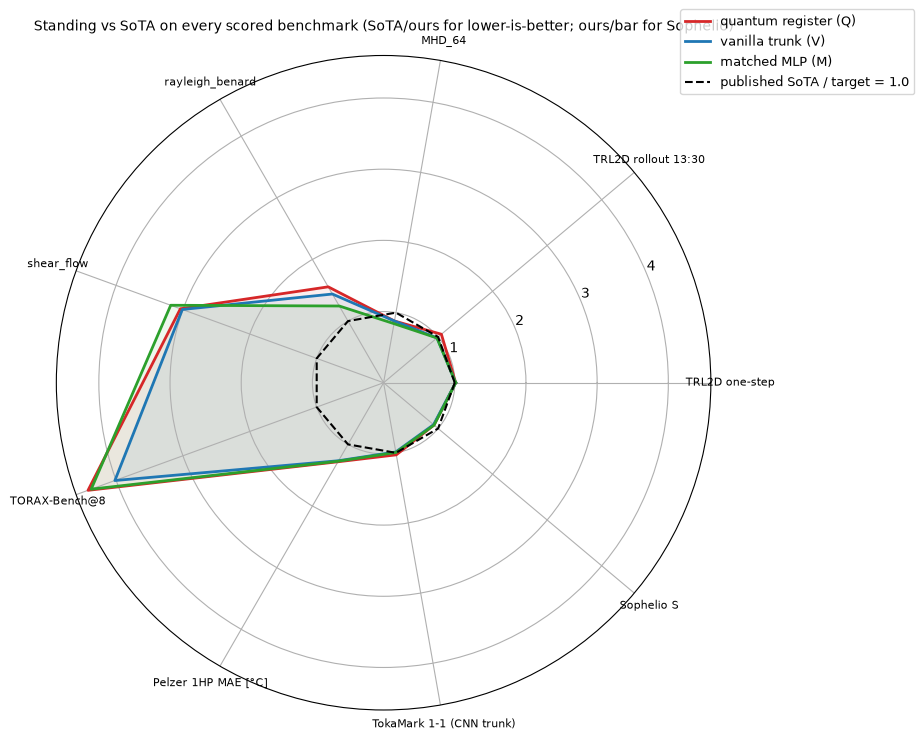

In [5]:

# ---- Radar: normalised standing vs SoTA (1.0 = the published number; >1 = better than SoTA) --------
done = board[board['q_n'] > 0].reset_index(drop=True)
def norm(row, a):
    return (row['sota'] / row[a]) if row['metric'] != 'S' else (row[a] / row['sota'])
labels = [b.replace(' VRMSE', '').replace(' TaskNRMSE', '') for b in done['benchmark']]
ang = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist(); ang += ang[:1]
fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw=dict(polar=True))
for a, c, lab in (('q', 'C3', 'quantum register (Q)'), ('vanilla', 'C0', 'vanilla trunk (V)'), ('mlp', 'C2', 'matched MLP (M)')):
    vals = [norm(r, a) for _, r in done.iterrows()]; vals += vals[:1]
    ax.plot(ang, vals, color=c, lw=2, label=lab); ax.fill(ang, vals, color=c, alpha=0.08)
ax.plot(ang, [1.0] * len(ang), color='k', lw=1.5, ls='--', label='published SoTA / target = 1.0')
ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=8); ax.set_ylim(0, max(2.6, ax.get_ylim()[1]))
ax.set_title('Standing vs SoTA on every scored benchmark (SoTA/ours for lower-is-better; ours/bar for Sophelio)', fontsize=10, pad=18)
ax.legend(loc='upper right', bbox_to_anchor=(1.32, 1.08), fontsize=9); plt.show()


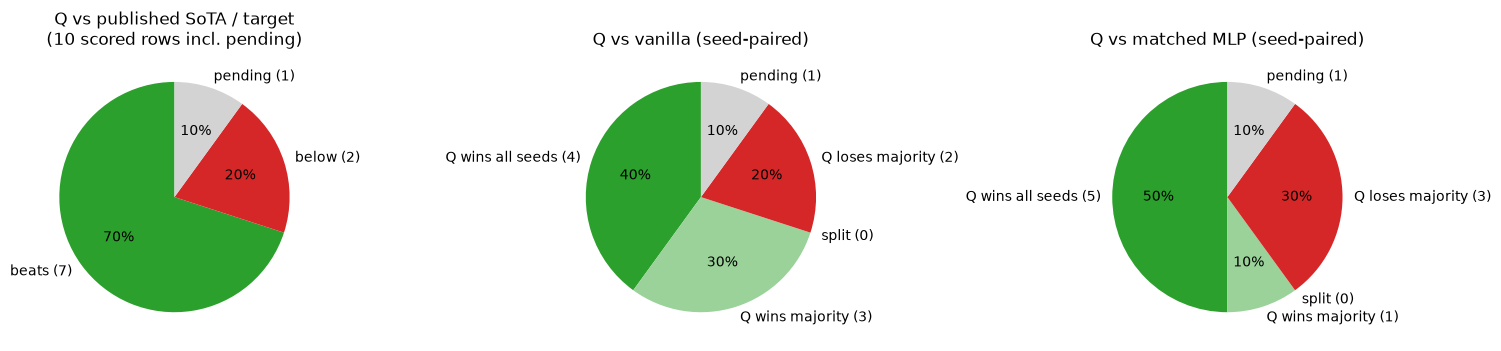

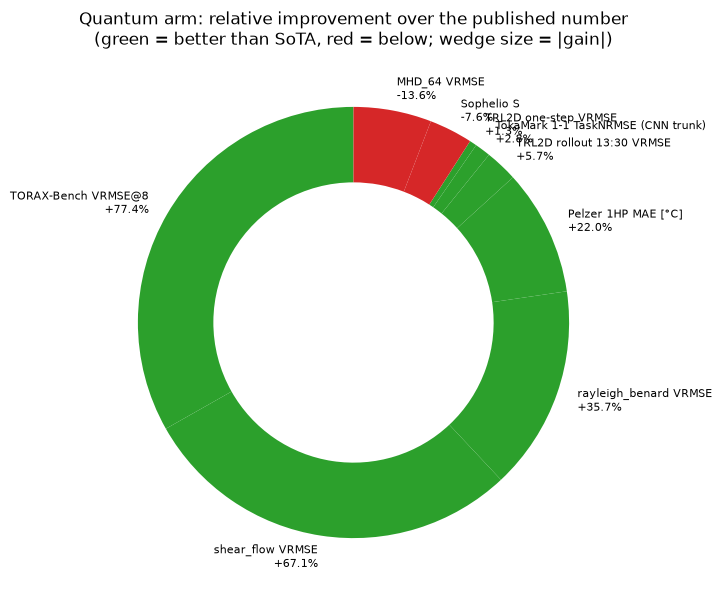

In [6]:

# ---- Pie charts: outcome of the quantum arm vs SoTA, vs vanilla and vs the matched MLP --------------
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
c1 = collections.Counter(board['q_vs_sota']); axs[0].pie([c1[k] for k in ('beats', 'below', 'pending')], labels=[f'{k} ({c1[k]})' for k in ('beats', 'below', 'pending')], colors=['C2', 'C3', 'lightgray'], autopct='%1.0f%%', startangle=90)
axs[0].set_title('Q vs published SoTA / target\n(' + str(len(board)) + ' scored rows incl. pending)')
def outcome(col):
    c = collections.Counter()
    for s in board[col]:
        if s == '-': c['pending'] += 1; continue
        w, n = map(int, s.split('/'))
        c['Q wins all seeds' if w == n else ('Q wins majority' if w > n / 2 else ('split' if w == n / 2 else 'Q loses majority'))] += 1
    return c
for ax, col, title in ((axs[1], 'q_wins_v', 'Q vs vanilla (seed-paired)'), (axs[2], 'q_wins_m', 'Q vs matched MLP (seed-paired)')):
    c = outcome(col); keys = ['Q wins all seeds', 'Q wins majority', 'split', 'Q loses majority', 'pending']
    ax.pie([c[k] for k in keys], labels=[f'{k} ({c[k]})' for k in keys if True], colors=['C2', '#9ad29a', 'khaki', 'C3', 'lightgray'], autopct=lambda p: f'{p:.0f}%' if p > 0 else '', startangle=90); ax.set_title(title)
plt.tight_layout(); plt.show()
# relative gain of Q over the SoTA number per benchmark (donut)
fig, ax = plt.subplots(figsize=(7, 7))
d2 = done.copy(); d2['gain'] = [(r['sota'] - r['q']) / r['sota'] * 100 if r['metric'] != 'S' else (r['q'] - r['sota']) / r['sota'] * 100 for _, r in d2.iterrows()]
d2 = d2.sort_values('gain', ascending=False)
colors = ['C2' if g > 0 else 'C3' for g in d2['gain']]
ax.pie(np.abs(d2['gain']) + 1e-9, labels=[f"{b}\n{g:+.1f}%" for b, g in zip(d2['benchmark'], d2['gain'])], colors=colors, wedgeprops=dict(width=0.35), startangle=90, textprops=dict(fontsize=8))
ax.set_title('Quantum arm: relative improvement over the published number\n(green = better than SoTA, red = below; wedge size = |gain|)'); plt.show()


## 6. Model outputs per benchmark (live from checkpoints)

### 6.1 Turbulence: The Well TRL2D (headline row)

test split (9, 101, 4, 128, 384) fields [('density', 1), ('pressure', 1), ('velocity', 2)]


loaded ['mr30ryd', 'mlp30', 'vanilla']


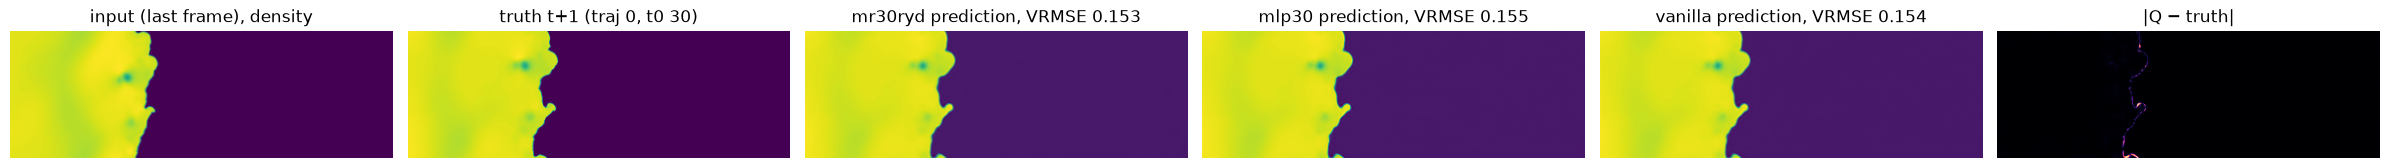

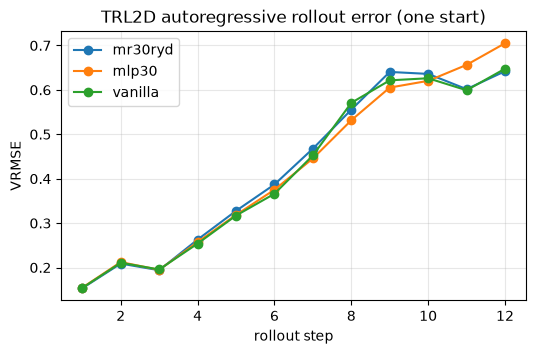

In [7]:

# ---- Model output 1: TRL2D (The Well) — headline checkpoint, one-step prediction and 8-step rollout ----
import well2d, cnext_hybrid
test = well2d.Split('turbulent_radiative_layer_2D', 'test')
print('test split', test.shape, 'fields', test.fields)
def load_trl(variant, path):
    m = cnext_hybrid.build_hybrid(variant); sd = torch.load(path, map_location='cpu')['model_state_dict']
    m.load_state_dict(sd, strict=False); return m.to(DEV).eval()
ckpts = {v: p for v, p in (('mr30ryd', ROOT / 'runs/phase_b/mr30ryd_s1337.pt'), ('mlp30', ROOT / 'runs/phase_b/mlp30_s1337.pt'), ('vanilla', ROOT / 'runs/phase_b/vanilla_s1337.pt')) if p.exists()}
models = {v: load_trl(v, p) for v, p in ckpts.items()}; print('loaded', list(models))
traj, t0 = 0, 30; x, y = test.window(traj, t0); C = test.C
with torch.no_grad():
    preds = {v: m(x[None].to(DEV))[0].cpu() for v, m in models.items()}
ch = 0  # density
fig, axs = plt.subplots(1, 3 + len(preds), figsize=(4 * (3 + len(preds)), 3.2))
axs[0].imshow(x[(well2d.N_HIST - 1) * C + ch], cmap='viridis'); axs[0].set_title('input (last frame), density')
axs[1].imshow(y[ch], cmap='viridis'); axs[1].set_title(f'truth t+1 (traj {traj}, t0 {t0})')
for i, (v, p) in enumerate(preds.items()):
    axs[2 + i].imshow(p[ch], cmap='viridis'); axs[2 + i].set_title(f'{v} prediction, VRMSE {well2d.vrmse_rows(p[None], y[None]).item():.3f}')
if 'mr30ryd' in preds:
    axs[-1].imshow((preds['mr30ryd'][ch] - y[ch]).abs(), cmap='magma'); axs[-1].set_title('|Q − truth|')
for a in axs: a.axis('off')
plt.tight_layout(); plt.show()
# rollout error vs horizon from the same start (autoregressive, feeding predictions back through the 4-frame history)
H = 12
frames = test.frames(traj, range(t0 - well2d.N_HIST + 1, t0 + H + 1))
curves = {}
with torch.no_grad():
    for v, m in models.items():
        hist = frames[:well2d.N_HIST].clone(); errs = []
        for h in range(H):
            p = m(hist.reshape(1, -1, test.H, test.W).to(DEV))[0].cpu()
            errs.append(well2d.vrmse_rows(p[None], frames[well2d.N_HIST + h][None]).item()); hist = torch.cat([hist[1:], p[None]], 0)
        curves[v] = errs
plt.figure(figsize=(6, 3.5))
for v, e in curves.items(): plt.plot(range(1, H + 1), e, marker='o', label=v)
plt.xlabel('rollout step'); plt.ylabel('VRMSE'); plt.title('TRL2D autoregressive rollout error (one start)'); plt.legend(); plt.grid(alpha=.3); plt.show()
test.close()


### 6.2 Fission proxy and shear turbulence: rayleigh_benard, shear_flow

rayleigh_benard (175, 200, 4, 512, 128) [('buoyancy', 1), ('pressure', 1), ('velocity', 2)]


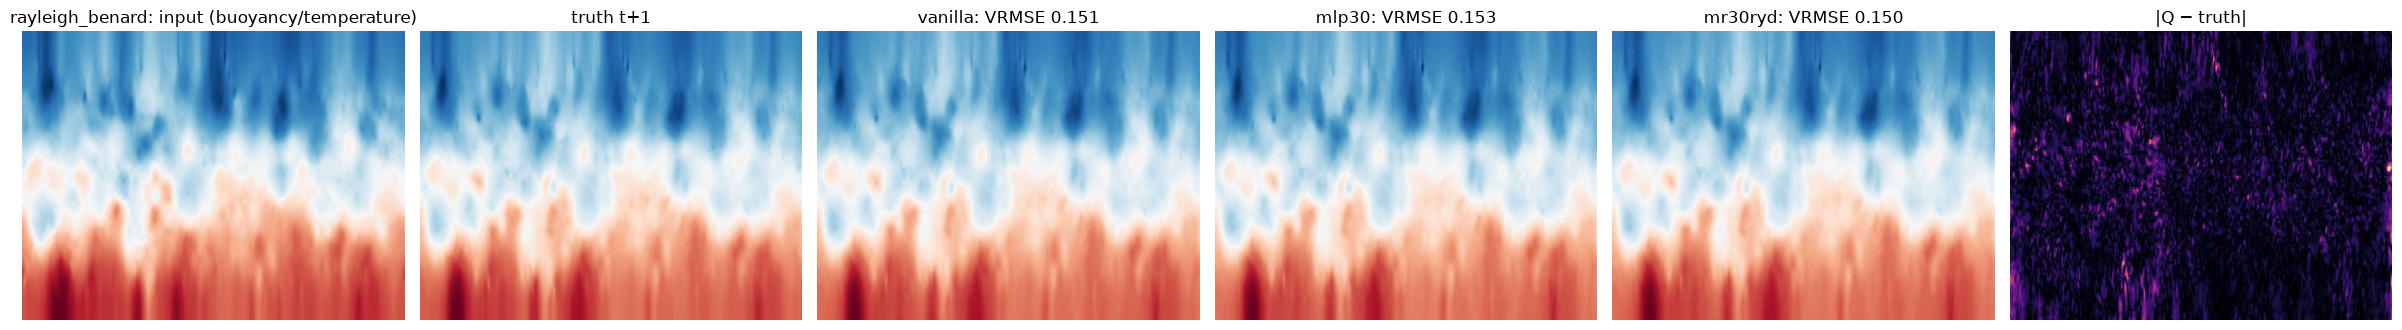

shear_flow (112, 200, 4, 256, 512) [('tracer', 1), ('pressure', 1), ('velocity', 2)]


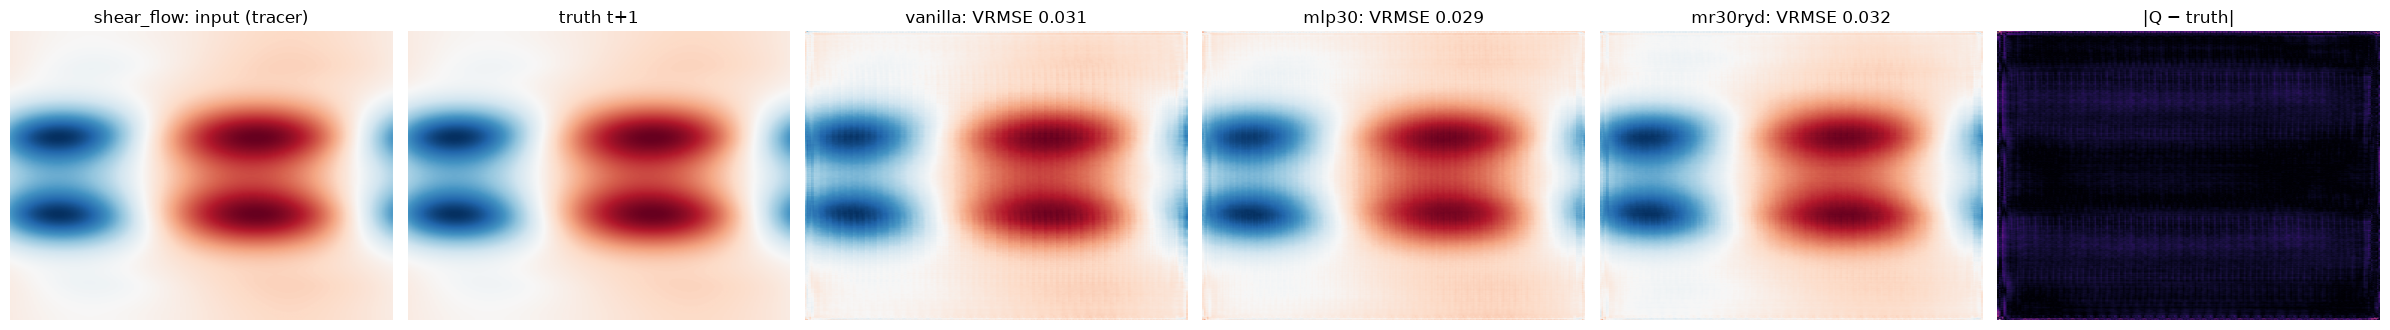

In [8]:

# ---- Model outputs 2–3: rayleigh_benard (fission proxy) and shear_flow — CNextU-net trunk checkpoints ----
import well2d_backbone
for ds, ch, cname in (('rayleigh_benard', 1, 'buoyancy/temperature'), ('shear_flow', 1, 'tracer')):
    split = well2d.Split(ds, 'test'); print(ds, split.shape, split.fields)
    ms = {v: well2d_backbone.load_checkpoint(v, ds, str(ROOT / f'runs/well2d/{ds}/cnext/{v}_s1337.pt'), 'cnext', DEV).eval() for v in ('vanilla', 'mlp30', 'mr30ryd') if (ROOT / f'runs/well2d/{ds}/cnext/{v}_s1337.pt').exists()}
    traj, t0 = min(3, split.n - 1), 60; x, y = split.window(traj, t0); C = split.C
    with torch.no_grad(): preds = {v: m(x[None].to(DEV))[0].cpu() for v, m in ms.items()}
    fig, axs = plt.subplots(1, 3 + len(preds), figsize=(4 * (3 + len(preds)), 3.4))
    axs[0].imshow(x[(well2d.N_HIST - 1) * C + ch].T, cmap='RdBu_r', aspect='auto'); axs[0].set_title(f'{ds}: input ({cname})')
    axs[1].imshow(y[ch].T, cmap='RdBu_r', aspect='auto'); axs[1].set_title('truth t+1')
    for i, (v, p) in enumerate(preds.items()):
        axs[2 + i].imshow(p[ch].T, cmap='RdBu_r', aspect='auto'); axs[2 + i].set_title(f'{v}: VRMSE {well2d.vrmse_rows(p[None], y[None]).item():.3f}')
    if 'mr30ryd' in preds: axs[-1].imshow((preds['mr30ryd'][ch] - y[ch]).abs().T, cmap='magma', aspect='auto'); axs[-1].set_title('|Q − truth|')
    for a in axs: a.axis('off')
    plt.tight_layout(); plt.show(); split.close()
    del ms; torch.cuda.empty_cache()


### 6.3 Geothermal: Pelzer 1HP heat plume

prepared 1000-run set (1000, 4, 256, 16) test 100


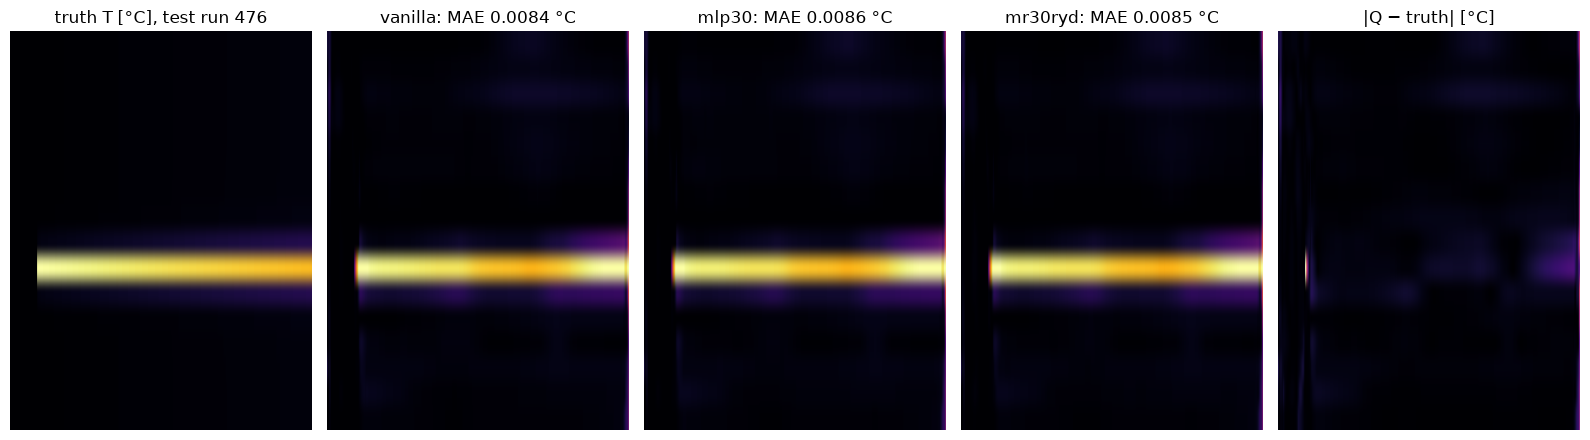

In [9]:

# ---- Model output 4: Pelzer 1HP geothermal heat plume — 1HP_NN U-Net trunk, our arms ----------------
import train_pelzer_unet as P
x, y, info, tr, va, te = P.load_1000(); print('prepared 1000-run set', tuple(x.shape), 'test', len(te))
D = P.D   # 1HP_NN's data module (denormalize_temperature, mae_celsius, pat)
ms = {}
for v in ('vanilla', 'mlp30', 'mr30ryd'):
    m = P.build(v); m.load_state_dict(torch.load(ROOT / f'runs/pelzer_unet/{v}_s1337.pt', map_location='cpu')['model_state_dict']); ms[v] = m.to(DEV).eval()
i = int(te[0]); xi, yi = x[i:i + 1].to(DEV), y[i:i + 1]
with torch.no_grad(): preds = {v: m(xi).cpu() for v, m in ms.items()}
tc = D.denormalize_temperature(yi, info)[0, 0].numpy()
fig, axs = plt.subplots(1, 2 + len(preds), figsize=(3.2 * (2 + len(preds)), 4.5))
axs[0].imshow(tc.T, cmap='inferno', aspect='auto'); axs[0].set_title('truth T [°C], test run %d' % i)
for k, (v, p) in enumerate(preds.items()):
    pc = D.denormalize_temperature(p, info)[0, 0].numpy(); mae = np.abs(pc - tc).mean()
    axs[1 + k].imshow(pc.T, cmap='inferno', aspect='auto', vmin=tc.min(), vmax=tc.max()); axs[1 + k].set_title(f'{v}: MAE {mae:.4f} °C')
pcq = D.denormalize_temperature(preds['mr30ryd'], info)[0, 0].numpy()
axs[-1].imshow(np.abs(pcq - tc).T, cmap='magma', aspect='auto'); axs[-1].set_title('|Q − truth| [°C]')
for a in axs: a.axis('off')
plt.tight_layout(); plt.show()


### 6.4 Fusion transport: TORAX-Bench

q30 trained in 356s: test VRMSE@1 0.0050, VRMSE@8 0.0280


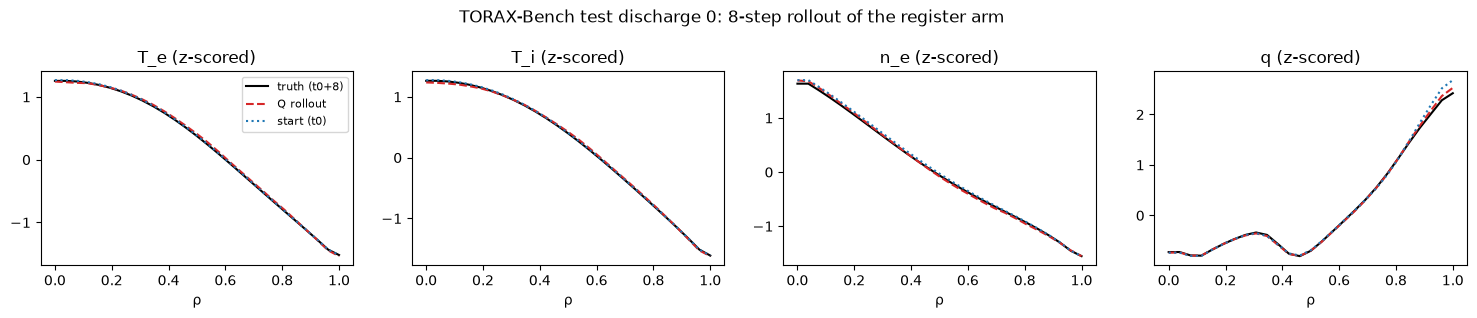

In [10]:

# ---- Model output 5: TORAX-Bench (our tokamak transport benchmark) — a fresh 1,000-step register arm ----
import bench_torax as B
d = B.data(); hp = dict(lr=1e-3, steps=1000, batch=16, wd=0.0)
t0 = time.time(); torch.manual_seed(1337)
model = B.build('q30').to(DEV); opt = torch.optim.Adam(model.parameters(), lr=hp['lr'])
Xtr, Ctr = d['train']; N, T = Xtr.shape[0], Xtr.shape[1]
for step in range(hp['steps']):
    b = torch.randint(0, N, (16,)); ti = torch.randint(0, T - 1 - B.K, (16,)); xx = Xtr[b, ti]; loss = 0.0
    for j in range(B.K): xx = model(xx, Ctr[b, ti + 1 + j]); loss = loss + ((xx - Xtr[b, ti + 1 + j]) ** 2).mean()
    opt.zero_grad(); (loss / B.K).backward(); opt.step()
Xte, Cte = d['test']; v1, v8 = B.evaluate(model, Xte, Cte); print(f'q30 trained in {time.time()-t0:.0f}s: test VRMSE@1 {v1:.4f}, VRMSE@8 {v8:.4f}')
# 8-step rollout profiles for one test discharge
i, s0 = 0, 20; xx = Xte[i:i + 1, s0]
with torch.no_grad():
    for j in range(8): xx = model(xx, Cte[i:i + 1, s0 + 1 + j])
truth = Xte[i, s0 + 8].cpu().numpy(); pred = xx[0].cpu().numpy(); rho = np.linspace(0, 1, truth.shape[-1])
fig, axs = plt.subplots(1, 4, figsize=(15, 3.2))
for c, name in enumerate(['T_e', 'T_i', 'n_e', 'q']):
    axs[c].plot(rho, truth[c], 'k-', label='truth (t0+8)'); axs[c].plot(rho, pred[c], 'C3--', label='Q rollout'); axs[c].plot(rho, Xte[i, s0, c].cpu().numpy(), 'C0:', label='start (t0)')
    axs[c].set_title(f'{name} (z-scored)'); axs[c].set_xlabel('ρ')
axs[0].legend(fontsize=8); plt.suptitle(f'TORAX-Bench test discharge {i}: 8-step rollout of the register arm'); plt.tight_layout(); plt.show()
del model; torch.cuda.empty_cache()


### 6.5 Fusion equilibrium from magnetics: TokaMark (real MAST)

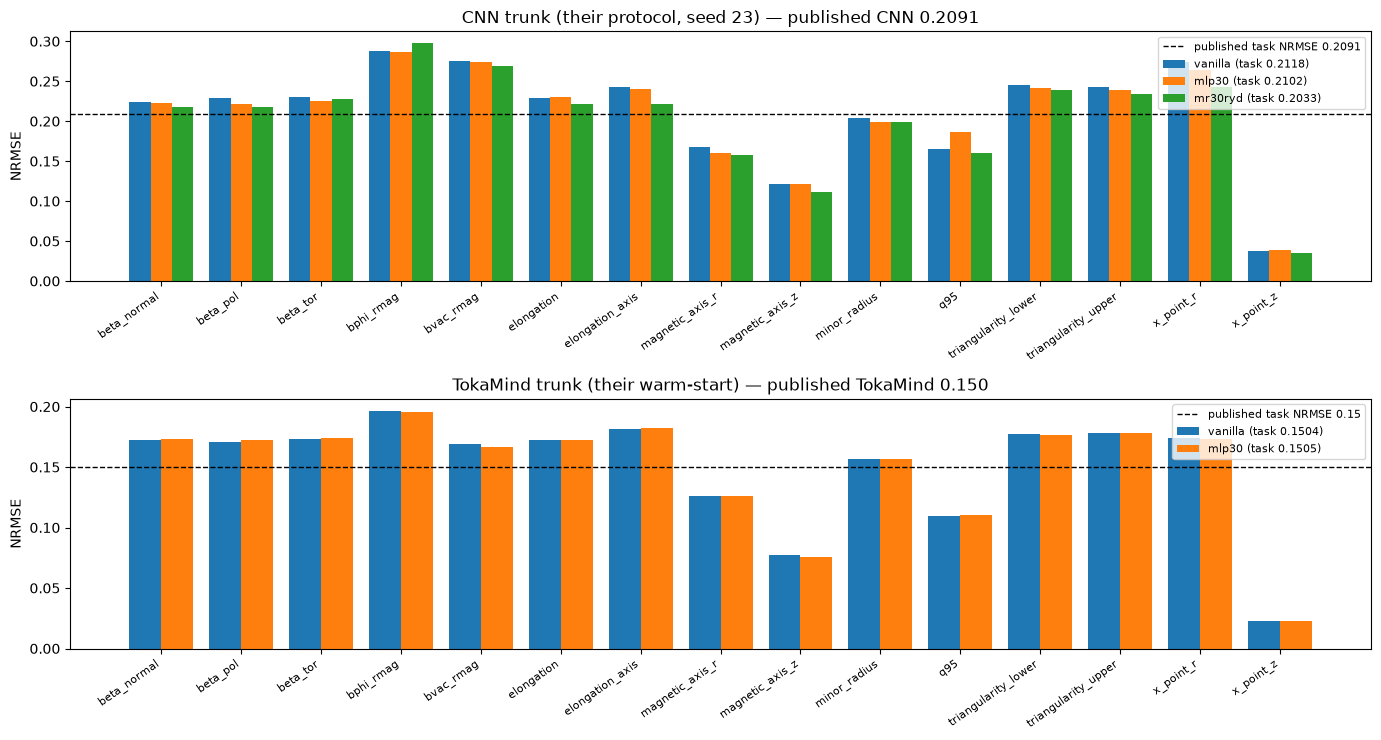

In [11]:

# ---- Model output 6: TokaMark task 1-1 (real MAST equilibria) — per-feature NRMSE, both trunks ---------
def feats_cnn(v):
    rows = list(csv.DictReader(open(ROOT / f'runs/tokamark/results/random/cnn_{v}/task_1-1/seed_23/task_1-1/task_metrics.csv')))
    return {r['feature_name'].replace('equilibrium-', ''): float(r['NRMSE_mean']) for r in rows if r['feature_name'] != 'task_1-1'}
def feats_tm(v):
    fs = [f for f in sorted(glob.glob(str(ROOT / f'runs/tokamark/results/tokamind_task_1-1_{v}_s*.json'))) if '_sub' not in f]
    if not fs: return None
    m = list(json.load(open(fs[0]))['task_metrics'].values())[0]
    return {k.replace('equilibrium-', ''): r['NRMSE_mean'] for k, r in m.items() if isinstance(r, dict) and k != 'task_1-1'}
fig, axs = plt.subplots(2, 1, figsize=(14, 7.5))
for ax, getter, title, pub in ((axs[0], feats_cnn, 'CNN trunk (their protocol, seed 23) — published CNN 0.2091', 0.2091), (axs[1], feats_tm, 'TokaMind trunk (their warm-start) — published TokaMind 0.150', 0.150)):
    data_ = {v: getter(v) for v in ('vanilla', 'mlp30', 'mr30ryd')}; data_ = {k: v for k, v in data_.items() if v}
    if not data_: ax.set_title(title + ' — pending'); continue
    names = list(next(iter(data_.values()))); xpos = np.arange(len(names)); w = 0.8 / len(data_)
    for k, (v, f) in enumerate(data_.items()):
        ax.bar(xpos + k * w, [f[n] for n in names], w, label=f"{v} (task {np.mean(list(f.values())):.4f})")
    ax.axhline(pub, color='k', ls='--', lw=1, label=f'published task NRMSE {pub}'); ax.set_xticks(xpos + 0.4 - w / 2); ax.set_xticklabels(names, rotation=35, ha='right', fontsize=8)
    ax.set_ylabel('NRMSE'); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


### 6.6 Fusion equilibrium challenge: Sophelio (DIII-D)

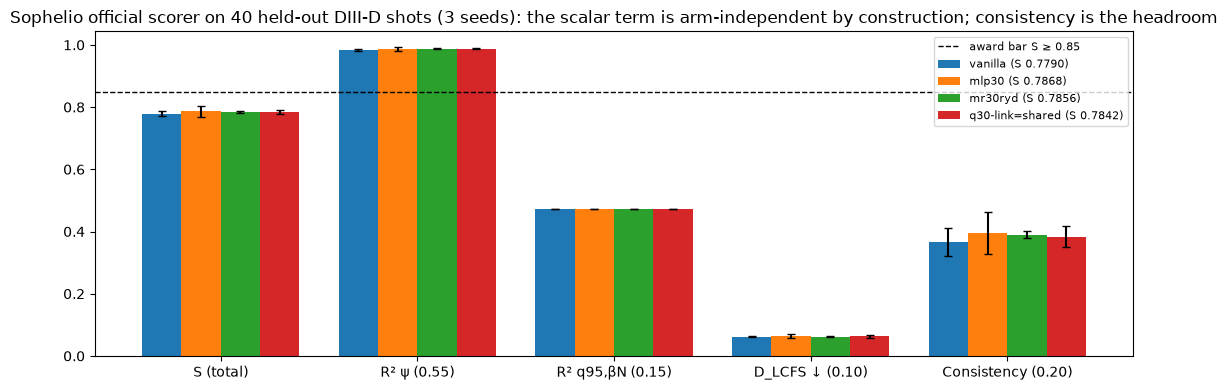

In [12]:

# ---- Model output 7: Sophelio equilibrium challenge — official score decomposition per arm ------------
terms = ['S', 'r2_psi', 'r2_qb', 'dlcfs', 'consistency']
fig, ax = plt.subplots(figsize=(11, 4))
arms = ['vanilla', 'mlp30', 'mr30ryd', 'q30-link=shared']; w = 0.8 / len(arms)
for k, v in enumerate(arms):
    vals = [[json.load(open(ROOT / f'runs/sophelio/{v}_s{s}.json'))['official'][t] for s in (1337, 1338, 1339)] for t in terms]
    ax.bar(np.arange(len(terms)) + k * w, [np.mean(x) for x in vals], w, yerr=[np.std(x) for x in vals], capsize=3, label=f"{v} (S {np.mean(vals[0]):.4f})")
ax.axhline(0.85, color='k', ls='--', lw=1, label='award bar S ≥ 0.85'); ax.set_xticks(np.arange(len(terms)) + 0.4 - w / 2); ax.set_xticklabels(['S (total)', 'R² ψ (0.55)', 'R² q95,βN (0.15)', 'D_LCFS ↓ (0.10)', 'Consistency (0.20)'])
ax.set_title('Sophelio official scorer on 40 held-out DIII-D shots (3 seeds): the scalar term is arm-independent by construction; consistency is the headroom'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()


## 7. Wave G: the register graph as a factor

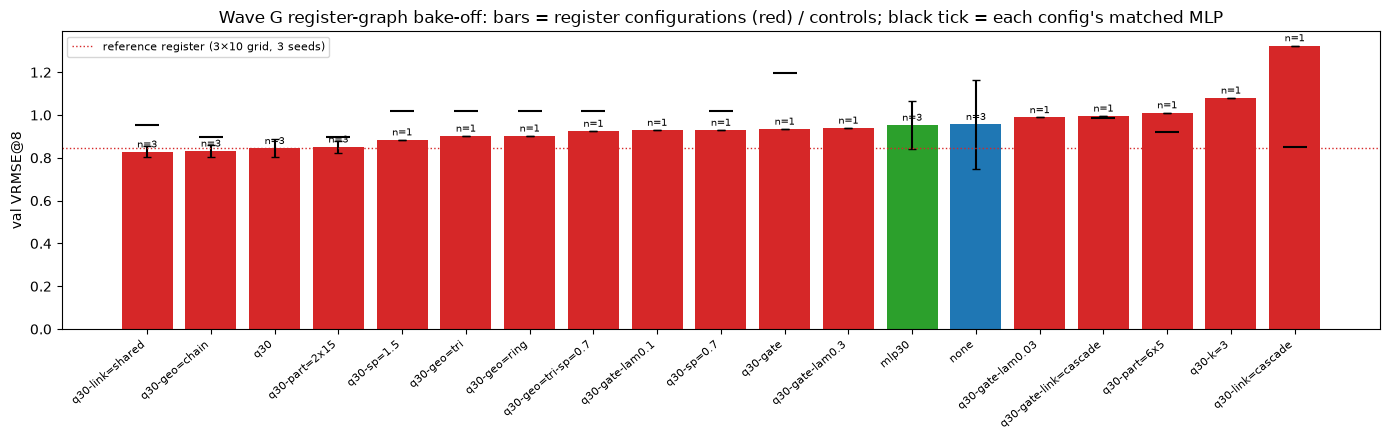

participation (qubits in use / 30): {'q30-link=cascade-mlp': np.float64(nan), 'q30-gate-mlp': np.float64(nan), 'q30-link=shared': np.float64(nan), 'q30-gate-link=cascade-mlp': np.float64(nan), 'q30-gate-lam0.1': np.float64(0.0), 'q30-gate-link=cascade': np.float64(0.986), 'q30-k=3-randk': np.float64(0.3), 'q30-k=3': np.float64(0.3), 'q30-gate': np.float64(0.985), 'q30-link=shared-mlp': np.float64(nan), 'q30-gate-lam0.03': np.float64(0.001), 'q30-gate-lam0.3': np.float64(0.0), 'q30-link=cascade': np.float64(nan)}


In [13]:

# ---- Wave G: the register graph as a factor (arena, fixed 2k steps, TD k=4) ----------------------------
def parse(f):
    t = open(f).read(); m8 = re.search(r'val_vrmse_8:\s+([0-9.]+)', t); pp = re.search(r'participation:\s+([0-9.]+)', t)
    return (float(m8.group(1)), float(pp.group(1)) if pp else np.nan) if m8 else None
runs = collections.defaultdict(dict)
for f in glob.glob(str(ROOT / 'runs/waveG/*_s*.log')):
    v, s = re.match(r'.*/(.+)_s(\d+)\.log$', f).groups(); r = parse(f)
    if r: runs[v][int(s)] = r
for alias, v in (('mr30ryd', 'q30'), ('mlp30', 'mlp30'), ('none', 'none')):
    for f in glob.glob(str(ROOT / f'runs/ag15_{alias}_k4_s*.log')):
        s = int(re.search(r'_s(\d+)\.log', f).group(1)); r = parse(f)
        if r and s not in runs[v]: runs[v][s] = r
order = [v for v in runs if not v.endswith('-mlp') and not v.endswith('-randk')]
order = sorted(order, key=lambda v: np.mean([x[0] for x in runs[v].values()]))
fig, ax = plt.subplots(figsize=(14, 4.5))
for i, v in enumerate(order):
    vals = [x[0] for x in runs[v].values()]; ax.bar(i, np.mean(vals), color='C3' if v.startswith('q') else ('C0' if v == 'none' else 'C2'), yerr=np.std(vals) if len(vals) > 1 else 0, capsize=3)
    ax.text(i, np.mean(vals) + 0.02, f'n={len(vals)}', ha='center', fontsize=7)
    ctl = runs.get(v + '-mlp');
    if ctl: ax.scatter([i], [np.mean([x[0] for x in ctl.values()])], marker='_', s=300, color='k', zorder=3)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=40, ha='right', fontsize=8); ax.set_ylabel('val VRMSE@8')
ax.axhline(np.mean([x[0] for x in runs['q30'].values()]), color='C3', ls=':', lw=1, label='reference register (3×10 grid, 3 seeds)')
ax.set_title('Wave G register-graph bake-off: bars = register configurations (red) / controls; black tick = each config\'s matched MLP'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
gated = {v: np.mean([x[1] for x in runs[v].values()]) for v in runs if 'gate' in v or 'k=' in v}
print('participation (qubits in use / 30):', {k: round(v, 3) for k, v in gated.items()})


## 8. Optuna HPO campaign (live)

In [14]:

# ---- Optuna HPO campaign (live): selected configurations and single-shot test results ----------------
for f in sorted(glob.glob(str(ROOT / 'runs/hpo/*/*_final.json'))):
    d = json.load(open(f)); print(f"{d['bench']:10s} {d['arm']:5s} valid {d['best_valid']:.5f} -> TEST {d['test_mean']:.5f} ± {d['test_sd']:.5f}  {d['variant']}  {d['hp']}")
print(open(ROOT / 'runs/hpo/status').read()[-1500:] if (ROOT / 'runs/hpo/status').exists() else 'no HPO status yet')


hpo runner start 2026-09-21T10:21:36+03:00
search torax none trials=16 2026-09-21T10:21:36+03:00




## 9. Reading the board honestly

- **Rows where the register is the only winning arm:** TRL2D long-horizon rollout (3/3 seeds vs both controls) and TokaMark on the CNN trunk (14/15 features vs vanilla, 13/15 vs MLP; one seed on their fixed-seed protocol).
- **Rows where all arms beat the published number:** rayleigh_benard, shear_flow, Pelzer — the gain belongs to the fine-tuning protocol as much as to the register; Q is the best mean on RB and Pelzer but not separable from the controls at three seeds.
- **Nulls:** MHD_64, TORAX (adapters beat the trunk, Q ≈ MLP), Sophelio (Q ≈ MLP; the award bar 0.85 needs a classical-side lift).
- **Graph configuration:** the shared-controller register is the first configuration to pass a pre-registered 3/3 rule on the arena; it did not transfer to TORAX, Pelzer or Sophelio, so configuration is searched per benchmark (the HPO campaign above).
- **Not claimed anywhere:** quantum advantage. Everything here runs on ≤ 30 exactly simulated qubits.

Pending: TokaMind-trunk 3×3 (running), Optuna-tuned rows (running), the two new industry benchmarks (materials/drug discovery, logistics/traffic), and the three video rows (parked for external hardware).
